In [1]:
import pandas as pd
import numpy as np

orders = pd.read_csv('../data/olist_orders_dataset.csv')
order_items = pd.read_csv("../data/olist_order_items_dataset.csv")

In [2]:
print("Orders dataset shape:", orders.shape)
print("Order items dataset shape:", order_items.shape)

Orders dataset shape: (99441, 8)
Order items dataset shape: (112650, 7)


In [3]:
sales_performance = pd.merge(
    orders, order_items, on='order_id', how='inner'
)



In [4]:
sales_performance.shape

(112650, 14)

In [5]:
sales_performance.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [6]:
sales_performance.dtypes

order_id                             str
customer_id                          str
order_status                         str
order_purchase_timestamp             str
order_approved_at                    str
order_delivered_carrier_date         str
order_delivered_customer_date        str
order_estimated_delivery_date        str
order_item_id                      int64
product_id                           str
seller_id                            str
shipping_limit_date                  str
price                            float64
freight_value                    float64
dtype: object

In [7]:
date_columns = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'order_purchase_timestamp',
    'shipping_limit_date'
]
for col in date_columns:
    sales_performance[col] = pd.to_datetime(sales_performance[col], errors='coerce')

In [8]:
sales_performance.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
order_item_id                             int64
product_id                                  str
seller_id                                   str
shipping_limit_date              datetime64[us]
price                                   float64
freight_value                           float64
dtype: object

In [9]:
sales_performance['revenue'] = sales_performance['price']

In [10]:
sales_performance['revenue'].sum()

np.float64(13591643.700000001)

In [11]:
sales_performance['purchase_year'] = sales_performance['order_purchase_timestamp'].dt.year
sales_performance['purchase_month'] = sales_performance['order_purchase_timestamp'].dt.month



In [12]:
sales_performance[['order_purchase_timestamp', 'purchase_year', 'purchase_month']].head()

,order_purchase_timestamp,purchase_year,purchase_month
0,2017-10-02 10:56:33,2017,10
1,2018-07-24 20:41:37,2018,7
2,2018-08-08 08:38:49,2018,8
3,2017-11-18 19:28:06,2017,11
4,2018-02-13 21:18:39,2018,2


In [13]:
#How does revenue change from month to month?
monthly_revenue = (
    sales_performance
    .groupby(['purchase_year', 'purchase_month'])['revenue']
    .sum()
    .reset_index()
)
monthly_revenue.head()

,purchase_year,purchase_month,revenue
0,2016,9,267.36
1,2016,10,49507.66
2,2016,12,10.90
3,2017,1,120312.87
4,2017,2,247303.02


In [14]:
monthly_revenue['year_month'] = pd.to_datetime({
    'year': monthly_revenue['purchase_year'],
    'month': monthly_revenue['purchase_month'],
    'day': 1
})

In [15]:
monthly_revenue

,purchase_year,purchase_month,revenue,year_month
0,2016,9,267.36,2016-09-01
1,2016,10,49507.66,2016-10-01
2,2016,12,10.90,2016-12-01
3,2017,1,120312.87,2017-01-01
4,2017,2,247303.02,2017-02-01
5,2017,3,374344.30,2017-03-01
6,2017,4,359927.23,2017-04-01
7,2017,5,506071.14,2017-05-01
8,2017,6,433038.60,2017-06-01
9,2017,7,498031.48,2017-07-01


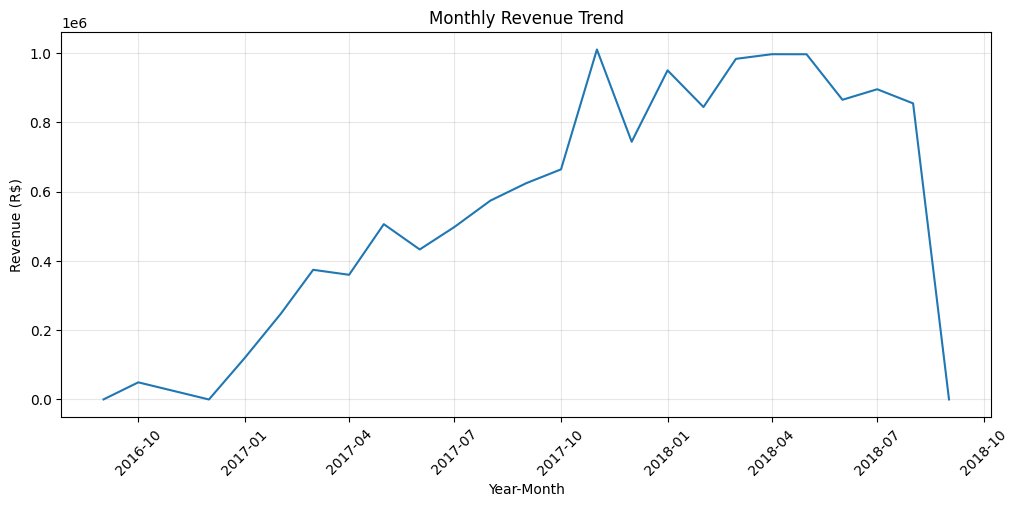

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.grid(True, alpha=0.3)
plt.plot(monthly_revenue['year_month'],monthly_revenue['revenue'])
plt.xlabel('Year-Month')
plt.ylabel('Revenue (R$)')
plt.title('Monthly Revenue Trend')
plt.xticks(rotation=45)
plt.show()

### Monthly Revenue Analysis — Key Findings

- Revenue showed an overall upward trend throughout 2017.
- November 2017 recorded the highest monthly revenue at R$1.01 million.
- Revenue remained relatively strong during the first eight months of 2018.
- A sharp decline occurred after August 2018, likely due to incomplete dataset coverage in the final months.

**Business Insight:** Olist demonstrated strong sales growth throughout the observed period. However, the incomplete data for September and October 2018 should be considered before drawing conclusions about the apparent revenue decline.

In [17]:
#monthly order volume
monthly_order_volume = (
    sales_performance
    .groupby(['purchase_year', 'purchase_month'])['order_id']
    .nunique()
    .reset_index()
)

monthly_order_volume = monthly_order_volume.rename(
    columns={'order_id': 'total_orders'}
)
monthly_order_volume

,purchase_year,purchase_month,total_orders
0,2016,9,3
1,2016,10,308
2,2016,12,1
3,2017,1,789
4,2017,2,1733
5,2017,3,2641
6,2017,4,2391
7,2017,5,3660
8,2017,6,3217
9,2017,7,3969


In [18]:
#average order value(AOV)
average_order_value = (
    monthly_revenue
    .merge(
        monthly_order_volume,
        on=['purchase_year', 'purchase_month'],
        how='inner'
    )
)
average_order_value['AOV'] = average_order_value['revenue'] / average_order_value['total_orders']
average_order_value

,purchase_year,purchase_month,revenue,year_month,total_orders,AOV
0,2016,9,267.36,2016-09-01,3,89.120000
1,2016,10,49507.66,2016-10-01,308,160.739156
2,2016,12,10.90,2016-12-01,1,10.900000
3,2017,1,120312.87,2017-01-01,789,152.487795
4,2017,2,247303.02,2017-02-01,1733,142.702262
5,2017,3,374344.30,2017-03-01,2641,141.743393
6,2017,4,359927.23,2017-04-01,2391,150.534182
7,2017,5,506071.14,2017-05-01,3660,138.270803
8,2017,6,433038.60,2017-06-01,3217,134.609450
9,2017,7,498031.48,2017-07-01,3969,125.480343


In [19]:
average_order_value.loc[average_order_value['AOV'].idxmax()]

purchase_year                    2016
purchase_month                     10
revenue                      49507.66
year_month        2016-10-01 00:00:00
total_orders                      308
AOV                        160.739156
Name: 1, dtype: object

In [20]:
average_order_value.loc[average_order_value['AOV'].idxmin()]

purchase_year                    2016
purchase_month                     12
revenue                          10.9
year_month        2016-12-01 00:00:00
total_orders                        1
AOV                              10.9
Name: 2, dtype: object

### AOV Analysis — Initial Findings

- Highest AOV: October 2016 (R$160.74), across 308 orders.
- Lowest AOV: December 2016 (R$10.90), based on only 1 order.
- November 2017 recorded the highest monthly revenue, but not the highest AOV.
- AOV and total revenue do not necessarily move together, as revenue is also influenced by order volume.

**Note:** Months with very few orders should be interpreted cautiously.

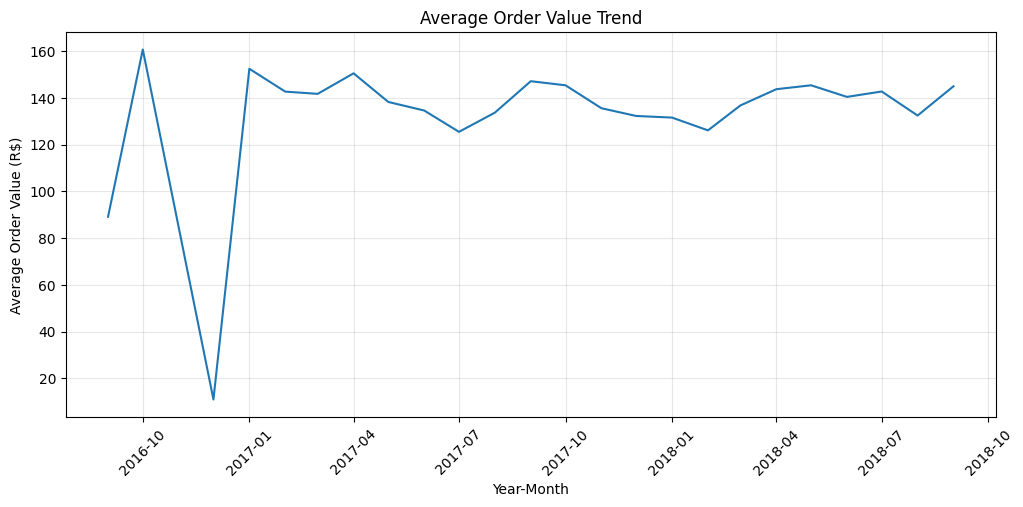

In [21]:
#AOV trend
plt.figure(figsize=(12, 5))
plt.grid(True, alpha=0.3)
plt.plot(average_order_value['year_month'], average_order_value['AOV'])
plt.xlabel('Year-Month')
plt.ylabel('Average Order Value (R$)')
plt.title('Average Order Value Trend')
plt.xticks(rotation=45)
plt.show()

### AOV Trend — Key Findings

- AOV fluctuated between approximately R$125 and R$152 throughout most of 2017 and 2018.
- October 2016 recorded the highest AOV (R$160.74).
- December 2016 recorded the lowest AOV (R$10.90), based on only one order.
- AOV remained relatively stable during 2017–2018.
- Months with very low order volumes require cautious interpretation.

**Business Insight:** Monthly revenue growth does not necessarily indicate an increase in average customer spending. Order volume and AOV should be evaluated together.

In [22]:
monthly_order_volume['year_month'] = pd.to_datetime({
    'year': monthly_order_volume['purchase_year'],
    'month': monthly_order_volume['purchase_month'],
    'day': 1
})

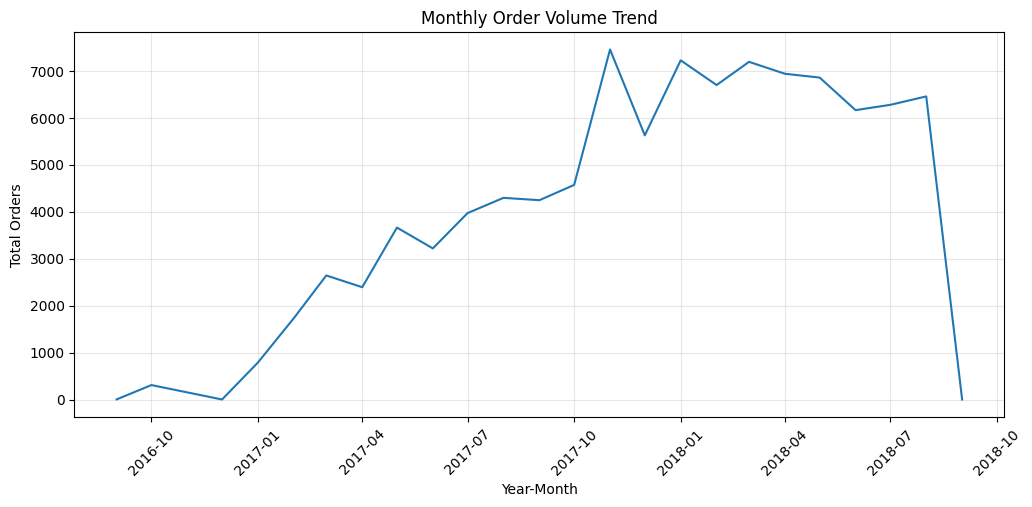

In [23]:
#Monthly Order Volume Trend
plt.figure(figsize=(12, 5))
plt.grid(True, alpha=0.3)
plt.plot(monthly_order_volume['year_month'], monthly_order_volume['total_orders'])
plt.xlabel('Year-Month')
plt.ylabel('Total Orders')
plt.title('Monthly Order Volume Trend')
plt.xticks(rotation=45)
plt.show()

### Monthly Order Volume — Key Findings

- Order volume increased significantly throughout 2017.
- November 2017 recorded the highest order volume, with 7,451 orders.
- Order volume remained relatively stable during most of 2018.
- September 2018 showed an unusually sharp decline, with only one order in the merged dataset.
- The final months have incomplete data coverage and should not be interpreted as actual business performance.

**Business Insight:** The marketplace experienced substantial order growth during 2017, followed by relatively stable order volumes in 2018.

In [24]:
#How is product sales value distributed across different order statuses?
status_revenue=sales_performance.groupby('order_status')['revenue'].sum().sort_values(ascending=False).reset_index()
status_revenue


,order_status,revenue
0,delivered,13221498.11
1,shipped,150727.44
2,canceled,95235.27
3,invoiced,61526.37
4,processing,60439.22
5,unavailable,2007.69
6,approved,209.60


In [25]:
status_revenue['revenue_percentage'] = status_revenue['revenue'] / status_revenue['revenue'].sum() * 100
status_revenue

,order_status,revenue,revenue_percentage
0,delivered,13221498.11,97.276668
1,shipped,150727.44,1.108971
2,canceled,95235.27,0.700690
3,invoiced,61526.37,0.452678
4,processing,60439.22,0.444679
5,unavailable,2007.69,0.014772
6,approved,209.60,0.001542


### Revenue by Order Status — Key Findings

- Delivered orders contribute 97.28% of total product revenue.
- Shipped orders contribute 1.11%.
- Canceled orders account for 0.70% of associated product value.
- Other order statuses contribute relatively small percentages.

**Business Insight:** Most recorded product sales value is associated with delivered orders. Revenue associated with non-delivered statuses requires separate investigation before being treated as realized revenue.

In [26]:
#how many order counts are there for each order status?
status_order_count = sales_performance.groupby('order_status')['order_id'].nunique().sort_values(ascending=False).reset_index()
status_order_count = status_order_count.rename(columns={'order_id': 'order_count'})
status_order_count

,order_status,order_count
0,delivered,96478
1,shipped,1106
2,canceled,461
3,invoiced,312
4,processing,301
5,unavailable,6
6,approved,2


### Order Status — Key Findings

- Delivered orders account for 96,478 unique orders.
- Shipped orders account for 1,106 orders.
- 461 canceled orders have associated order-item records.
- Only 6 unavailable orders appear in the merged sales dataset.
- Order counts differ from the original orders dataset because the analysis uses an inner join with order items.

**Business Insight:** Delivered orders dominate marketplace activity. However, the merged dataset excludes orders without matching order-item records, so status counts should be interpreted within the scope of the sales dataset.

In [27]:
status_order_count['order_percentage'] = (
    status_order_count['order_count'] /
    status_order_count['order_count'].sum() * 100
)
status_order_count

,order_status,order_count,order_percentage
0,delivered,96478,97.782417
1,shipped,1106,1.120954
2,canceled,461,0.467233
3,invoiced,312,0.316218
4,processing,301,0.305070
5,unavailable,6,0.006081
6,approved,2,0.002027


In [28]:
status_analysis = status_order_count.merge(
    status_revenue,
    on='order_status',
    how='inner'
)
status_analysis


,order_status,order_count,order_percentage,revenue,revenue_percentage
0,delivered,96478,97.782417,13221498.11,97.276668
1,shipped,1106,1.120954,150727.44,1.108971
2,canceled,461,0.467233,95235.27,0.700690
3,invoiced,312,0.316218,61526.37,0.452678
4,processing,301,0.305070,60439.22,0.444679
5,unavailable,6,0.006081,2007.69,0.014772
6,approved,2,0.002027,209.60,0.001542


### Order Status Performance — Key Findings

- Delivered orders account for 97.78% of order volume and 97.28% of product revenue.
- Canceled orders represent 0.47% of orders but 0.70% of associated product value.
- Shipped and delivered orders contribute similar proportions of order volume and revenue.
- Non-delivered statuses have a relatively small share of total recorded product value.

**Business Insight:** Canceled orders account for a disproportionately higher share of product value than order volume. This may indicate that canceled orders tend to have higher-than-average item values.

In [29]:
#What is the average product value per order for each order status
status_analysis['average_order_value'] = status_analysis['revenue'] / status_analysis['order_count']
status_analysis

,order_status,order_count,order_percentage,revenue,revenue_percentage,average_order_value
0,delivered,96478,97.782417,13221498.11,97.276668,137.041586
1,shipped,1106,1.120954,150727.44,1.108971,136.281591
2,canceled,461,0.467233,95235.27,0.700690,206.584100
3,invoiced,312,0.316218,61526.37,0.452678,197.199904
4,processing,301,0.305070,60439.22,0.444679,200.794751
5,unavailable,6,0.006081,2007.69,0.014772,334.615000
6,approved,2,0.002027,209.60,0.001542,104.800000


### Average Order Value by Status — Key Findings

- Delivered orders have an average product value of R$137.04.
- Canceled orders have a higher average product value of R$206.58.
- Processing and invoiced orders also have relatively high average values.
- Unavailable orders show the highest average value (R$334.62), but only 6 orders are represented.

**Business Insight:** Canceled orders have a higher average product value than delivered orders. This could indicate that higher-value purchases are more likely to be canceled, although further investigation is needed to establish the reason.

In [30]:
sales_performance.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date',
       'price', 'freight_value', 'revenue', 'purchase_year', 'purchase_month'],
      dtype='str')

In [31]:
products = pd.read_csv("../data/olist_products_dataset.csv")
category_translation = pd.read_csv("../data/product_category_name_translation.csv")

In [32]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')

In [33]:
category_translation.columns

Index(['product_category_name', 'product_category_name_english'], dtype='str')

In [34]:
category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [35]:
products_translated = products.merge(
    category_translation,
    on='product_category_name',
    how='left'
)
products_translated

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,housewares
...,...,...,...,...,...,...,...,...,...,...
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,40.0,40.0,40.0,furniture_decor
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,16.0,19.0,16.0,construction_tools_lights
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,27.0,7.0,27.0,bed_bath_table
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,31.0,13.0,20.0,computers_accessories


In [36]:
products_translated.shape

(32951, 10)

In [37]:
products_translated['product_category_name_final'] = products_translated['product_category_name_english'].fillna(products_translated['product_category_name'])

In [38]:
products_translated['product_category_name_final'].isna().sum()

np.int64(610)

In [39]:
products_translated['product_category_name_final'].nunique()

73

In [40]:
products_translated['product_category_name_final'].value_counts().head(10)

product_category_name_final
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64

In [41]:
sales_category = pd.merge(
    sales_performance,
    products_translated[['product_id', 'product_category_name_final']],
    on='product_id',
    how='left'
)
sales_category.shape

(112650, 18)

In [42]:
sales_category.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,revenue,purchase_year,purchase_month,product_category_name_final
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,29.99,2017,10,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,118.70,2018,7,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,159.90,2018,8,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,45.00,2017,11,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,19.90,2018,2,stationery


In [43]:
print(sales_category['product_category_name_final'].isna().sum())
print(sales_category['product_id'].nunique())

1603
32951


In [44]:
category_revenue = (
    sales_category
    .groupby('product_category_name_final')['revenue']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
category_revenue.head(10)

,product_category_name_final,revenue
0,health_beauty,1258681.34
1,watches_gifts,1205005.68
2,bed_bath_table,1036988.68
3,sports_leisure,988048.97
4,computers_accessories,911954.32
5,furniture_decor,729762.49
6,cool_stuff,635290.85
7,housewares,632248.66
8,auto,592720.11
9,garden_tools,485256.46


### Product Category Revenue — Key Findings

- Health & Beauty generated the highest revenue (R$1.26 million).
- Watches & Gifts ranked second with R$1.21 million.
- Bed, Bath & Table ranked third with R$1.04 million.
- The top two categories generated relatively similar revenue.
- Garden Tools ranked tenth among the top 10 categories.

**Business Insight:** Health & Beauty and Watches & Gifts are the leading revenue-generating categories in the marketplace.

In [45]:
category_quantity = (
    sales_category
    .groupby('product_category_name_final')['order_id']
    .size()
    .sort_values(ascending=False)
    .reset_index()
)
category_quantity = category_quantity.rename(columns={'order_id': 'items_sold'})
category_quantity.head(10)

,product_category_name_final,items_sold
0,bed_bath_table,11115
1,health_beauty,9670
2,sports_leisure,8641
3,furniture_decor,8334
4,computers_accessories,7827
5,housewares,6964
6,watches_gifts,5991
7,telephony,4545
8,garden_tools,4347
9,auto,4235


In [46]:
category_performance = category_revenue.merge(
    category_quantity,
    on='product_category_name_final',
    how='inner'
)
category_performance.head(10)

,product_category_name_final,revenue,items_sold
0,health_beauty,1258681.34,9670
1,watches_gifts,1205005.68,5991
2,bed_bath_table,1036988.68,11115
3,sports_leisure,988048.97,8641
4,computers_accessories,911954.32,7827
5,furniture_decor,729762.49,8334
6,cool_stuff,635290.85,3796
7,housewares,632248.66,6964
8,auto,592720.11,4235
9,garden_tools,485256.46,4347


In [47]:
category_performance['average_selling_price'] = category_performance['revenue'] / category_performance['items_sold']
category_performance.head(10)

,product_category_name_final,revenue,items_sold,average_selling_price
0,health_beauty,1258681.34,9670,130.163531
1,watches_gifts,1205005.68,5991,201.135984
2,bed_bath_table,1036988.68,11115,93.296327
3,sports_leisure,988048.97,8641,114.344285
4,computers_accessories,911954.32,7827,116.513903
5,furniture_decor,729762.49,8334,87.564494
6,cool_stuff,635290.85,3796,167.357969
7,housewares,632248.66,6964,90.788148
8,auto,592720.11,4235,139.957523
9,garden_tools,485256.46,4347,111.630196


In [48]:
category_performance.sort_values(
    by='average_selling_price',
    ascending=False
).head(10)

,product_category_name_final,revenue,items_sold,average_selling_price
16,computers,222963.13,203,1098.340542
34,small_appliances_home_oven_and_coffee,47445.71,76,624.285658
25,home_appliances_2,113317.74,238,476.124958
28,agro_industry_and_commerce,72530.47,212,342.124858
18,musical_instruments,191498.88,680,281.616000
19,small_appliances,190648.58,679,280.778468
61,portateis_cozinha_e_preparadores_de_alimentos,3968.53,15,264.568667
30,fixed_telephony,59583.00,264,225.693182
38,construction_tools_safety,40544.52,194,208.992371
1,watches_gifts,1205005.68,5991,201.135984


In [49]:
category_performance.sort_values(
    by='average_selling_price',
    ascending=True
).head(10)

,product_category_name_final,revenue,items_sold,average_selling_price
69,home_comfort_2,760.27,30,25.342333
68,flowers,1110.04,33,33.637576
66,diapers_and_hygiene,1567.59,39,40.194615
70,cds_dvds_musicals,730.00,14,52.142857
50,food_drink,15179.48,278,54.602446
53,christmas_supplies,8800.82,153,57.521699
40,food,29393.41,510,57.634137
20,electronics,160246.74,2767,57.913531
62,fashio_female_clothing,2803.64,48,58.409167
45,drinks,22428.70,379,59.178628


## Product Category Performance — Key Findings

### Revenue
- Health & Beauty generated the highest revenue (R$1.26 million).
- Watches & Gifts ranked second (R$1.21 million).

### Sales Volume
- Bed, Bath & Table recorded the highest item sales (11,115).
- Health & Beauty ranked second (9,670).

### Average Selling Price
- Computers recorded the highest ASP (R$1,098.34).
- Home Comfort 2 recorded the lowest ASP (R$25.34).
- Watches & Gifts combined relatively high ASP with substantial sales volume.

### Business Insights
- High revenue does not necessarily indicate high item volume.
- Categories can generate revenue through higher prices or higher sales quantities.
- Average prices in categories with few transactions should be interpreted cautiously.

In [50]:
customers = pd.read_csv("../data/olist_customers_dataset.csv")
print(customers.shape)
print(orders.shape)

(99441, 5)
(99441, 8)


In [51]:
customer_orders = pd.merge(
    customers,
    orders,
    on='customer_id',
    how='inner'
)
customer_orders.head(10)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05 00:00:00
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06 00:00:00
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13 00:00:00
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10 00:00:00
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15 00:00:00
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC,5741ea1f91b5fbab2bd2dc653a5b5099,delivered,2017-09-14 18:14:31,2017-09-14 18:25:11,2017-09-18 21:27:40,2017-09-28 17:32:43,2017-10-04 00:00:00
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP,36e694cf4cbc2a4803200c35e84abdc4,delivered,2018-02-19 14:38:35,2018-02-19 14:50:37,2018-02-20 00:03:39,2018-02-20 16:25:51,2018-03-05 00:00:00
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG,1093c8304c7a003280dd34598194913d,delivered,2017-11-16 19:29:02,2017-11-16 19:55:41,2017-11-22 16:46:33,2017-11-27 12:44:36,2017-12-08 00:00:00
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR,1ebeea841c590e86a14a0d7a48e7d062,delivered,2018-01-18 12:35:44,2018-01-18 12:56:32,2018-01-18 23:25:35,2018-01-26 15:17:57,2018-02-20 00:00:00
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG,7433cbcc783205509d66a5260da5b574,delivered,2018-01-08 11:22:34,2018-01-08 11:35:27,2018-01-11 01:00:40,2018-01-13 14:51:55,2018-02-05 00:00:00


In [52]:
customer_purchase_frequency = (
    customer_orders
    .groupby('customer_unique_id')['order_id']
    .nunique()
    .reset_index()
)
customer_purchase_frequency = customer_purchase_frequency.rename(columns={'order_id': 'purchase_count'})
customer_purchase_frequency.head()

,customer_unique_id,purchase_count
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


In [53]:
customer_purchase_frequency['purchase_count'].value_counts().sort_index()

purchase_count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

In [54]:
one_time_customers = customer_purchase_frequency.loc[customer_purchase_frequency['purchase_count'] == 1]
repeat_customers = customer_purchase_frequency.loc[customer_purchase_frequency['purchase_count'] > 1]
one_time_count = one_time_customers.shape[0]
repeat_count = repeat_customers.shape[0]
print(f"One-time customers: {one_time_count}")
print(f"Repeat customers: {repeat_count}")

One-time customers: 93099
Repeat customers: 2997


In [55]:
one_time_percentage = (one_time_count / customer_purchase_frequency.shape[0]) * 100
repeat_percentage = (repeat_count / customer_purchase_frequency.shape[0]) * 100
print(f"Percentage of one-time customers: {one_time_percentage:.2f}%")
print(f"Percentage of repeat customers: {repeat_percentage:.2f}%")

Percentage of one-time customers: 96.88%
Percentage of repeat customers: 3.12%


### Customer Purchase Frequency — Key Findings

- Total unique customers: 96,096.
- One-time customers: 93,099 (96.88%).
- Repeat customers: 2,997 (3.12%).
- One customer recorded 17 purchases.
- Most customers made only one purchase during the observation period.
- Repeat customers placed an average of 2.12 orders during the observation period.

**Business Insight:** The marketplace has a low repeat-purchase share, suggesting an opportunity to investigate customer retention and repeat-purchase behaviour.

In [56]:
repeat_customers['purchase_count'].mean()

np.float64(2.116116116116116)

In [57]:
#Where are the marketplace's customers concentrated?
customer_state_distribution = customer_orders.groupby('customer_state')['customer_unique_id'].nunique().sort_values(ascending=False).reset_index()
customer_state_distribution = customer_state_distribution.rename(columns={'customer_unique_id': 'unique_customers'})
customer_state_distribution

,customer_state,unique_customers
0,SP,40302
1,RJ,12384
2,MG,11259
3,RS,5277
4,PR,4882
5,SC,3534
6,BA,3277
7,DF,2075
8,ES,1964
9,GO,1952


### Customer Geographical Analysis — Key Findings

- São Paulo (SP) has the highest customer count (40,302).
- Rio de Janeiro (RJ) and Minas Gerais (MG) rank second and third.
- The top three states account for approximately 66.6% of unique customers.
- Customer distribution is heavily concentrated in southeastern Brazil.

**Business Insight:** São Paulo is the marketplace's strongest customer market. Regional marketing and logistics strategies could prioritize areas with high customer concentration.

In [58]:
customer_sales = sales_performance.merge(
    customer_orders[['order_id', 'customer_unique_id', 'customer_state']],
    on='order_id',
    how='left'
)

In [59]:
print(customer_sales.shape)
print(customer_sales.columns)

(112650, 19)
Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date',
       'price', 'freight_value', 'revenue', 'purchase_year', 'purchase_month',
       'customer_unique_id', 'customer_state'],
      dtype='str')


In [60]:
#Which Brazilian states generate the highest product revenue
state_revenue = customer_sales.groupby('customer_state')['revenue'].sum().sort_values(ascending=False).reset_index()
state_revenue

,customer_state,revenue
0,SP,5202955.05
1,RJ,1824092.67
2,MG,1585308.03
3,RS,750304.02
4,PR,683083.76
5,SC,520553.34
6,BA,511349.99
7,DF,302603.94
8,GO,294591.95
9,ES,275037.31


### Key Insights — Revenue by Customer State

- São Paulo generated the highest product revenue (R$5.20M).
- Rio de Janeiro and Minas Gerais followed with R$1.82M and R$1.59M, respectively.
- The top three states contributed approximately 68% of the product revenue.
- Revenue is geographically concentrated in Brazil's Southeast region.

**Business Implication:** The marketplace has a strong customer revenue base in Southeast Brazil. This region could be important when prioritizing regional marketing and customer retention strategies.

In [61]:
#Revenue per customer by state
state_customer_revenue = customer_sales.groupby(['customer_state', 'customer_unique_id'])['revenue'].sum().reset_index()
state_customer_revenue

,customer_state,customer_unique_id,revenue
0,AC,005ee3e015ec18092d7782e507cf68fe,159.99
1,AC,057e56752630652c673205286270e5a3,179.00
2,AC,05cf4ddb31059a169df61046881d812f,189.94
3,AC,0845d810b482f4d469d3c88380f4a7d5,524.90
4,AC,086d6b5b5ba195a91aa0a6ec8e75d1a4,961.60
...,...,...,...
95453,TO,fe64246944cea1dd63421ee753223b56,37.80
95454,TO,feeca5dd91115b235c4655f3265f3d38,84.44
95455,TO,ff49f630f4f29f0ef0599808148e1298,199.90
95456,TO,ffc111c45b1be48abf79c9ffcab4be40,69.00


In [62]:
state_customer_summary = (
    state_customer_revenue
    .groupby('customer_state')
    .agg(
        total_revenue=('revenue', 'sum'),
        unique_customers=('customer_unique_id', 'nunique')
    )
    .reset_index()
)
state_customer_summary['average_revenue_per_customer'] = (
    state_customer_summary['total_revenue'] /
    state_customer_summary['unique_customers']
)
state_customer_summary.sort_values(
    by='average_revenue_per_customer',
    ascending=False
)

,customer_state,total_revenue,unique_customers,average_revenue_per_customer
14,PB,115268.08,516,223.387752
0,AC,15982.95,77,207.570779
1,AL,80314.81,399,201.290251
3,AP,13474.30,67,201.108955
20,RO,46140.64,235,196.343149
13,PA,178947.81,944,189.563358
26,TO,49621.74,272,182.432868
16,PI,86914.08,481,180.694553
12,MT,156453.53,873,179.213666
19,RN,83034.98,471,176.295074


### Key Insights — Average Revenue per Customer by State

- Paraíba recorded the highest average revenue per customer at R$223.39.
- São Paulo generated the highest total revenue but had the lowest average revenue per customer at R$130.14.
- Several states with smaller customer bases recorded higher average revenue per customer.
- Total revenue and average customer revenue reveal different aspects of regional performance.

**Business Implication:** The marketplace could investigate customer spending patterns in high-average-revenue states while exploring opportunities to increase average spending in larger markets such as São Paulo.

**Note:** Averages from states with smaller customer bases should be interpreted cautiously.

In [63]:
payments = pd.read_csv("../data/olist_order_payments_dataset.csv")
print(payments.head())
print(payments.shape)
print(payments.info())

                           order_id  payment_sequential payment_type  \
0  b81ef226f3fe1789b1e8b2acac839d17                   1  credit_card   
1  a9810da82917af2d9aefd1278f1dcfa0                   1  credit_card   
2  25e8ea4e93396b6fa0d3dd708e76c1bd                   1  credit_card   
3  ba78997921bbcdc1373bb41e913ab953                   1  credit_card   
4  42fdf880ba16b47b59251dd489d4441a                   1  credit_card   

   payment_installments  payment_value  
0                     8          99.33  
1                     1          24.39  
2                     1          65.71  
3                     8         107.78  
4                     2         128.45  
(103886, 5)
<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2

In [64]:
payments['payment_type'].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [65]:
plt.figure(figsize=(4, 4))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,
    labeldistance=1.12
)

plt.title('Payment Method Distribution')
plt.tight_layout()
plt.show()

NameError: name 'payment_counts' is not defined

<Figure size 400x400 with 0 Axes>

In [ ]:
#Which payment method contributes the highest total payment value?
payment_values = payments.groupby('payment_type')['payment_value'].sum().sort_values(ascending=False).reset_index()
payment_values

,payment_type,payment_value
0,credit_card,12542084.19
1,boleto,2869361.27
2,voucher,379436.87
3,debit_card,217989.79
4,not_defined,0.00


### Key Insights — Payment Value by Method

- Credit cards account for approximately 77.35% of total payment value.
- Boleto contributes approximately 17.70%.
- Credit cards contribute a larger share of payment value than their share of payment records.
- Voucher and debit card payments account for relatively small portions of total payment value.

**Business Implication:** Credit cards are the dominant payment method in both transaction frequency and payment value.

In [ ]:
#Average Payment Value
payment_analysis = (
    payments
    .groupby('payment_type')
    .agg(
        total_payment=('payment_value', 'sum'),
        payment_count=('payment_value', 'count')
    )
    .reset_index()
)
payment_analysis['average_payment_value'] = (
    payment_analysis['total_payment'] /
    payment_analysis['payment_count']
)
payment_analysis.sort_values(
    by='average_payment_value',
    ascending=False
).round(2)

,payment_type,total_payment,payment_count,average_payment_value
1,credit_card,12542084.19,76795,163.32
0,boleto,2869361.27,19784,145.03
2,debit_card,217989.79,1529,142.57
4,voucher,379436.87,5775,65.70
3,not_defined,0.00,3,0.00


In [ ]:
#How many installments do customers generally choose when paying by credit card?
credit_card_payments = payments[payments['payment_type'] == 'credit_card']
credit_card_payments['payment_installments'].value_counts().sort_index()


payment_installments
0         2
1     25455
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

### Key Insights — Credit Card Installments

- One installment was the most frequently selected option, with 25,455 payment records.
- Two and three installments were the next most popular choices.
- A smaller number of customers selected longer installment plans.
- Two records contained zero installments and were retained for analysis.

**Business Insight:** Single-installment payments were more common than any other installment option. However, customers also demonstrated demand for spreading payments across multiple installments.

In [ ]:
#How common is installment payment?
more_than_one_installment = credit_card_payments[
    credit_card_payments['payment_installments'] > 1
]

one_installment = credit_card_payments[
    credit_card_payments['payment_installments'] == 1
]
more_than_one_percentage = (more_than_one_installment.shape[0] / credit_card_payments.shape[0]) * 100
one_installment_percentage = (one_installment.shape[0] / credit_card_payments.shape[0]) * 100
print(f"Percentage of credit card payments with more than one installment: {more_than_one_percentage:.2f}%")
print(f"Percentage of credit card payments with one installment: {one_installment_percentage:.2f}%")

Percentage of credit card payments with more than one installment: 66.85%
Percentage of credit card payments with one installment: 33.15%


### Key Insights — Credit Card Installment Behaviour

- 66.85% of credit-card payment records used more than one installment.
- 33.15% used exactly one installment.
- Multiple-installment payments were more common than single-installment payments.

**Business Implication:** Flexible installment options appear relevant to customer payment behaviour and may support purchasing flexibility.

In [ ]:
#Does choosing more installments correspond to a higher payment value?
installment_analysis = (
    credit_card_payments
    .groupby('payment_installments')
    .agg(
        payment_count=('payment_value', 'count'),
        average_payment=('payment_value', 'mean')
    )
    .reset_index()
)

installment_analysis


,payment_installments,payment_count,average_payment
0,0,2,94.315000
1,1,25455,95.872930
2,2,12413,127.228150
3,3,10461,142.539317
4,4,7098,163.976840
5,5,5239,183.465222
6,6,3920,209.849952
7,7,1626,187.673672
8,8,4268,307.737427
9,9,644,203.440870


### Key Insights — Installment Analysis

- One installment was the most popular credit-card payment option, with 25,455 records.
- Two and three installments were the next most frequently selected options.
- Average payment value generally increased with installment count.
- The 10-installment group recorded an average payment value of R$415.09 across 5,328 records.
- Higher installment groups had fewer observations and should be interpreted cautiously.

**Business Implication:** Customers use both single-payment and installment options. Higher-value payment records appear more common in several multi-installment groups, suggesting that flexible payment options may be relevant for higher-value purchases.

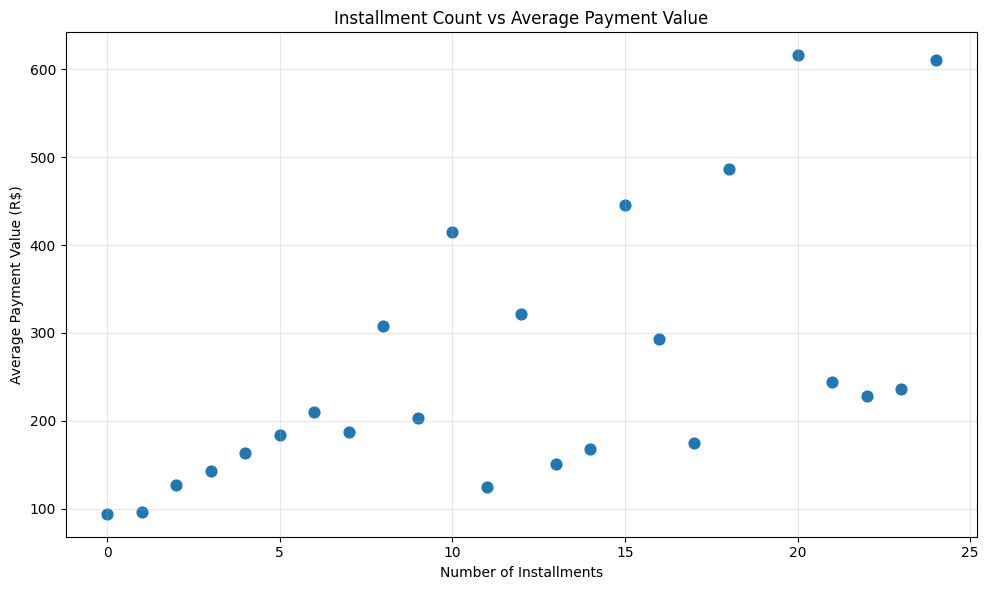

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    installment_analysis['payment_installments'],
    installment_analysis['average_payment'],
    s=60
)

plt.title('Installment Count vs Average Payment Value')
plt.xlabel('Number of Installments')
plt.ylabel('Average Payment Value (R$)')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
payment_frequency = payments.groupby('order_id').size()

multiple_payments = payment_frequency[payment_frequency > 1]

single_payment = payment_frequency[payment_frequency == 1]
total_orders = payment_frequency.shape[0]

multiple_payment_count = multiple_payments.shape[0]
single_payment_count = single_payment.shape[0]

multiple_payment_percentage = (multiple_payment_count / total_orders) * 100
single_payment_percentage = (single_payment_count / total_orders) * 100

print("Orders with multiple payments:", multiple_payment_count)
print("Orders with single payments:", single_payment_count)
print(f"Multiple payment percentage: {multiple_payment_percentage:.2f}%")
print(f"Single payment percentage: {single_payment_percentage:.2f}%")

Orders with multiple payments: 2961
Orders with single payments: 96479
Multiple payment percentage: 2.98%
Single payment percentage: 97.02%


### Key Insights — Multiple Payment Analysis

- 97.02% of orders had a single payment record.
- 2.98% of orders had multiple payment records.
- Most orders were associated with a single payment record.

**Business Implication:** Single-record payments dominate marketplace transactions, while a smaller proportion of orders involve multiple payment records.

In [70]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 13.0 MB


In [69]:
date_columns = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'order_approved_at',
    'order_delivered_carrier_date',
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [71]:
orders['actual_delivery_days'] = (
    orders['order_delivered_customer_date'] -
    orders['order_purchase_timestamp']
).dt.days

In [73]:
orders['actual_delivery_days'].describe()

count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: actual_delivery_days, dtype: float64

### Key Insights — Actual Delivery Time

- Average delivery time was approximately 12.09 days.
- Median delivery time was 10 days.
- 25% of orders were delivered within 6 days.
- 75% of orders were delivered within 15 days.
- The maximum delivery time was 209 days, indicating potential extreme delays.

**Business Insight:** Most orders were delivered within 15 days, but the large gap between the median and maximum suggests that some customers experienced significantly longer delivery times.

In [74]:
orders[orders['actual_delivery_days'] > 30][
    ['order_id', 'actual_delivery_days']
].sort_values(by='actual_delivery_days', ascending=False)

,order_id,actual_delivery_days
19590,ca07593549f1816d26a572e06dc1eab6,209.0
55619,1b3190b2dfa9d789e1f14c05b647a14a,208.0
61610,440d0d17af552815d15a9e41abe49359,195.0
70307,2fb597c2f772eca01b1f5c561bf6cc7b,194.0
89130,285ab9426d6982034523a855f55a885e,194.0
...,...,...
11219,93b94a19e5546ce4eac9c4eac62f5465,31.0
11523,1bf4871c57b8284ca1dfa1a02ad278c6,31.0
12464,4cfc21861f949b1bb4f23340193a2138,31.0
24854,40ded1def93af58d921116148bcc30e7,31.0


In [75]:
orders[orders['actual_delivery_days'] > 60].shape[0]

288

In [76]:
(orders['actual_delivery_days'].gt(60).sum() /
 orders['actual_delivery_days'].notna().sum()) * 100

np.float64(0.2985198391309756)

### Key Insights — Long Delivery Durations

- 4,118 orders (4.27%) took more than 30 days to reach customers.
- 288 orders (0.30%) took more than 60 days.
- The maximum recorded delivery duration was 209 days.
- Extremely long delivery durations were relatively uncommon but deserve further investigation.

**Business Insight:** Although most orders were delivered within 15 days, a small proportion experienced substantial delivery delays.

In [79]:
orders['delivery_difference_days'] = (
    orders['order_delivered_customer_date'] -
    orders['order_estimated_delivery_date']
).dt.days
orders['delivery_difference_days'].describe()

count    96476.000000
mean       -11.876881
std         10.183854
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: delivery_difference_days, dtype: float64

In [80]:
early_deliveries = orders[orders['delivery_difference_days'] < 0]

on_time_deliveries = orders[orders['delivery_difference_days'] == 0]

late_deliveries = orders[orders['delivery_difference_days'] > 0]
print("Early deliveries:", early_deliveries.shape[0])
print("On-time deliveries:", on_time_deliveries.shape[0])
print("Late deliveries:", late_deliveries.shape[0])

Early deliveries: 88649
On-time deliveries: 1292
Late deliveries: 6535


### Key Insights — Delivery Performance

- 91.88% of delivered orders arrived earlier than estimated.
- 1.34% arrived exactly on the estimated delivery date.
- 6.77% arrived later than estimated.
- A total of 6,535 delivered orders experienced delays.

**Business Insight:** Most orders arrived before their estimated delivery dates. However, the late-delivery group represents an opportunity to improve logistics reliability and customer experience.

In [82]:
delivery_state = orders.merge(
    customers[['customer_id', 'customer_state']],
    on='customer_id',
    how='left'
)
delivery_state.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days,delivery_difference_days,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.0,-8.0,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.0,-6.0,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.0,-18.0,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.0,-13.0,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.0,-10.0,SP


In [83]:
print(delivery_state.shape)
print(delivery_state.columns)

(99441, 11)
Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'actual_delivery_days', 'delivery_difference_days', 'customer_state'],
      dtype='str')


In [84]:
delivery_state['is_late'] = (
    delivery_state['delivery_difference_days'] > 0
)

In [85]:
delivered_orders = delivery_state[
    (delivery_state['order_status'] == 'delivered') &
    (delivery_state['delivery_difference_days'].notna())
]

In [86]:
delivery_by_state = (
    delivered_orders
    .groupby('customer_state')
    .agg(
        total_orders=('order_id', 'nunique'),
        late_orders=('is_late', 'sum'),
        average_delivery_days=('actual_delivery_days', 'mean')
    )
    .reset_index()
)

In [87]:
delivery_by_state['late_delivery_percentage'] = (
    delivery_by_state['late_orders'] /
    delivery_by_state['total_orders'] * 100
)

In [88]:
delivery_by_state.sort_values(
    by='late_delivery_percentage',
    ascending=False
).round(2)

,customer_state,total_orders,late_orders,average_delivery_days,late_delivery_percentage
1,AL,397,85,24.04,21.41
9,MA,717,125,21.12,17.43
24,SE,335,51,21.03,15.22
16,PI,476,66,18.99,13.87
5,CE,1279,176,20.82,13.76
21,RR,41,5,28.98,12.20
4,BA,3256,396,18.87,12.16
18,RJ,12350,1495,14.85,12.11
13,PA,946,106,23.32,11.21
7,ES,1995,214,15.33,10.73


### Key Insights — Delivery Performance by State

- Alagoas recorded the highest late delivery rate at 21.41%.
- Maranhão followed with 17.43%.
- São Paulo had the highest number of late orders (1,820), but its late delivery rate was relatively low at 4.49%.
- Rio de Janeiro recorded 1,495 late orders, with a late delivery rate of 12.11%.
- Late delivery rates varied considerably across Brazilian states.

**Business Implication:** The marketplace could investigate logistics operations in states with higher late delivery rates, while considering both delay percentages and order volumes when prioritizing improvements.

In [90]:
delivery_by_state.sort_values(
    by='average_delivery_days',
    ascending=False
).head(10)

,customer_state,total_orders,late_orders,average_delivery_days,late_delivery_percentage
21,RR,41,5,28.975610,12.195122
3,AP,67,2,26.731343,2.985075
2,AM,145,4,25.986207,2.758621
1,AL,397,85,24.040302,21.410579
13,PA,946,106,23.316068,11.205074
9,MA,717,125,21.117155,17.433752
24,SE,335,51,21.029851,15.223881
5,CE,1279,176,20.817826,13.760751
0,AC,80,3,20.637500,3.750000
14,PB,517,54,19.953578,10.444874


### Key Insights — Average Delivery Time by State

- Roraima recorded the longest average delivery time at approximately 28.98 days.
- Amapá and Amazonas followed with 26.73 and 25.99 days.
- Alagoas recorded an average delivery time of 24.04 days and the highest late delivery rate (21.41%).
- São Paulo had a comparatively low average delivery time of 8.30 days and a late delivery rate of 4.49%.
- Delivery speed and late delivery rates varied considerably across states.

**Business Implication:** Logistics improvements should consider both average delivery duration and late delivery rates. States with smaller order volumes should be interpreted cautiously.

In [91]:
delivery_state['purchase_year_month'] = (
    delivery_state['order_purchase_timestamp'].dt.to_period('M')
)

In [92]:
monthly_delivery = (
    delivery_state
    .groupby('purchase_year_month')['actual_delivery_days']
    .mean()
    .reset_index(name='average_delivery_days')
)

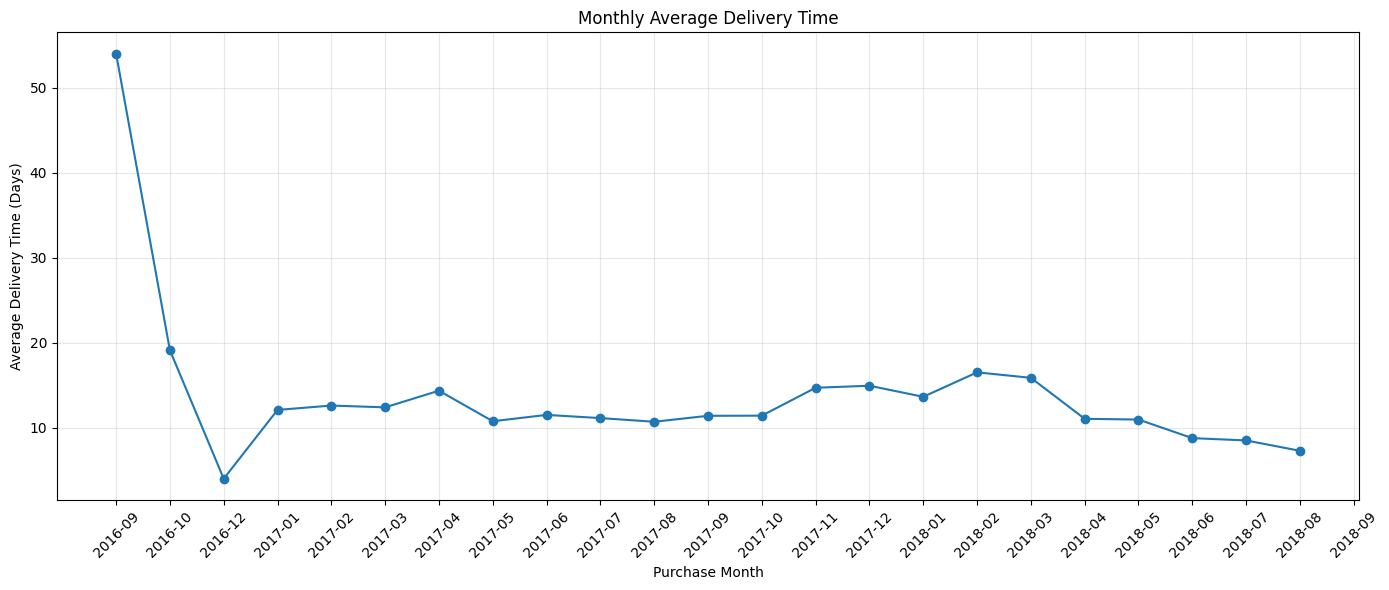

In [93]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_delivery['purchase_year_month'].astype(str),
    monthly_delivery['average_delivery_days'],
    marker='o'
)

plt.title('Monthly Average Delivery Time')
plt.xlabel('Purchase Month')
plt.ylabel('Average Delivery Time (Days)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
monthly_delivery.loc[
    monthly_delivery['average_delivery_days'].idxmax()
]

purchase_year_month      2016-09
average_delivery_days       54.0
Name: 0, dtype: object

In [95]:
monthly_delivery.loc[
    monthly_delivery['average_delivery_days'].idxmin()
]

purchase_year_month      2016-12
average_delivery_days        4.0
Name: 2, dtype: object

### Key Insights — Monthly Delivery Trends

- September 2016 recorded the highest average delivery time at 54 days.
- December 2016 recorded the lowest average at 4 days.
- Throughout 2017, average delivery time generally remained between 10 and 15 days.
- Delivery times increased temporarily during February and March 2018.
- From April to August 2018, average delivery time generally decreased.
- August 2018 recorded an average delivery time of approximately 7 days.

**Business Insight:** Delivery performance showed signs of improvement during 2018. However, monthly variations and differences in order volume should be considered before drawing firm conclusions.

In [98]:
reviews = pd.read_csv("../data/olist_order_reviews_dataset.csv")
print(reviews.head())
print(reviews.shape)
print(reviews.info())

                          review_id                          order_id  \
0  7bc2406110b926393aa56f80a40eba40  73fc7af87114b39712e6da79b0a377eb   
1  80e641a11e56f04c1ad469d5645fdfde  a548910a1c6147796b98fdf73dbeba33   
2  228ce5500dc1d8e020d8d1322874b6f0  f9e4b658b201a9f2ecdecbb34bed034b   
3  e64fb393e7b32834bb789ff8bb30750e  658677c97b385a9be170737859d3511b   
4  f7c4243c7fe1938f181bec41a392bdeb  8e6bfb81e283fa7e4f11123a3fb894f1   

   review_score review_comment_title  \
0             4                  NaN   
1             5                  NaN   
2             5                  NaN   
3             5                  NaN   
4             5                  NaN   

                              review_comment_message review_creation_date  \
0                                                NaN  2018-01-18 00:00:00   
1                                                NaN  2018-03-10 00:00:00   
2                                                NaN  2018-02-17 00:00:00   
3           

In [99]:
review_counts = reviews['review_score'].value_counts().sort_index()

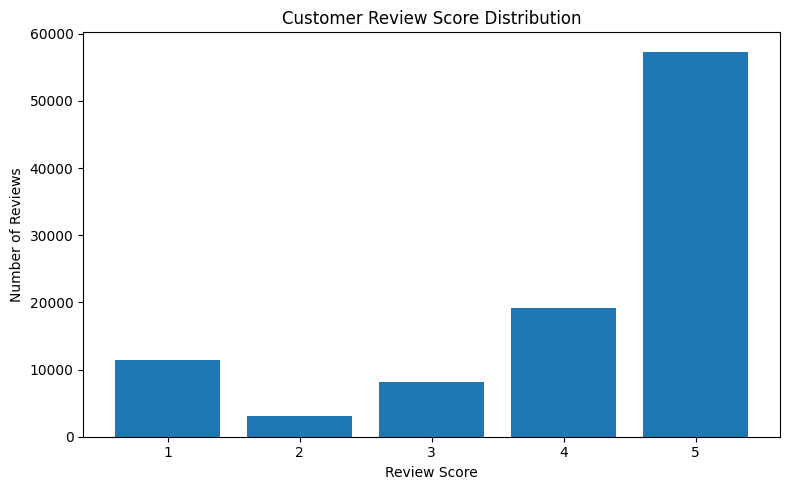

In [100]:
plt.figure(figsize=(8, 5))

plt.bar(review_counts.index, review_counts.values)

plt.title('Customer Review Score Distribution')
plt.xlabel('Review Score')
plt.ylabel('Number of Reviews')
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

In [102]:
reviews['review_score'].describe()

count    99224.000000
mean         4.086421
std          1.347579
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64

In [103]:
#Do customers who experience late deliveries tend to give lower review scores?
review_delivery = reviews.merge(
    delivery_state[
        ['order_id', 'delivery_difference_days', 'actual_delivery_days']
    ],
    on='order_id',
    how='inner'
)
review_delivery.shape

(99224, 9)

In [104]:
review_delivery.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,delivery_difference_days,actual_delivery_days
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,-16.0,6.0
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13,-5.0,9.0
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24,-21.0,13.0
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,-20.0,10.0
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53,-9.0,18.0


In [106]:
review_delivery['delivery_status'] = 'Unknown'

review_delivery.loc[
    review_delivery['delivery_difference_days'] < 0,
    'delivery_status'
] = 'Early'

review_delivery.loc[
    review_delivery['delivery_difference_days'] == 0,
    'delivery_status'
] = 'On Time'

review_delivery.loc[
    review_delivery['delivery_difference_days'] > 0,
    'delivery_status'
] = 'Late'

In [107]:
delivery_review_analysis = (
    review_delivery
    .groupby('delivery_status')['review_score']
    .agg(['mean', 'count'])
    .reset_index()
)

delivery_review_analysis

,delivery_status,mean,count
0,Early,4.293578,88658
1,Late,2.271139,6410
2,On Time,4.033308,1291
3,Unknown,1.761257,2865


### Key Insights — Delivery Performance vs Customer Satisfaction

- Early deliveries received an average review score of 4.29.
- On-time deliveries received an average score of 4.03.
- Late deliveries received a significantly lower average score of 2.27.
- The difference between early and late delivery ratings was approximately 2.02 points.

**Business Insight:** Late deliveries are strongly associated with lower customer satisfaction. Improving delivery reliability could help improve the customer experience.

**Note:** This analysis identifies an association, not proof that delivery delays alone caused lower ratings.

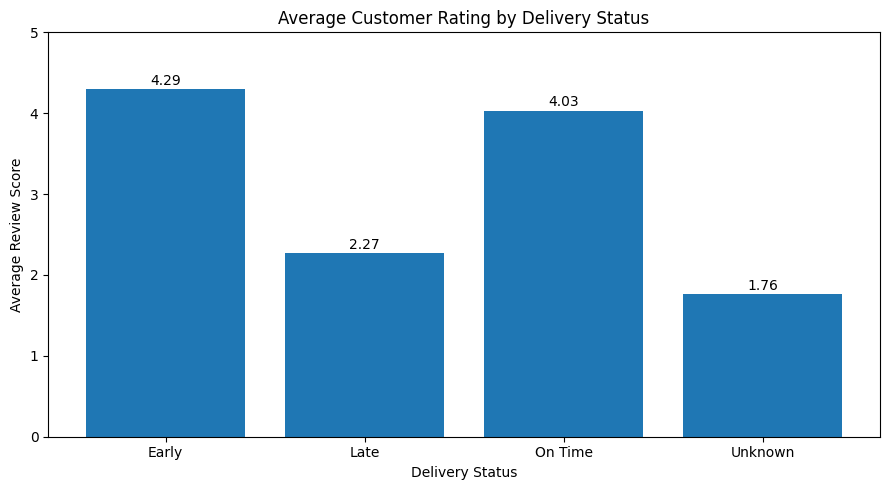

In [109]:
plt.figure(figsize=(9, 5))

plt.bar(
    delivery_review_analysis['delivery_status'],
    delivery_review_analysis['mean']
)
for i, value in enumerate(delivery_review_analysis['mean']):
    plt.text(i, value + 0.05, f'{value:.2f}', ha='center')
plt.title('Average Customer Rating by Delivery Status')
plt.xlabel('Delivery Status')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

In [111]:
#review scores by state
review_customers = reviews.merge(
    orders[['order_id', 'customer_id']],
    on='order_id',
    how='left'
)

review_customers = review_customers.merge(
    customers[['customer_id', 'customer_state']],
    on='customer_id',
    how='left'
)
review_customers.shape

(99224, 9)

In [112]:
review_customers.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,customer_id,customer_state
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,41dcb106f807e993532d446263290104,SP
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13,8a2e7ef9053dea531e4dc76bd6d853e6,SP
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24,e226dfed6544df5b7b87a48208690feb,BA
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,de6dff97e5f1ba84a3cd9a3bc97df5f6,SC
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53,5986b333ca0d44534a156a52a8e33a83,SC


In [113]:
review_by_state = (
    review_customers
    .groupby('customer_state')
    .agg(
        average_review_score=('review_score', 'mean'),
        total_reviews=('review_score', 'count')
    )
    .reset_index()
)

review_by_state

,customer_state,average_review_score,total_reviews
0,AC,4.049383,81
1,AL,3.751208,414
2,AM,4.183673,147
3,AP,4.194030,67
4,BA,3.860888,3357
5,CE,3.851016,1329
6,DF,4.064711,2148
7,ES,4.041667,2016
8,GO,4.042490,2024
9,MA,3.764075,746


In [114]:
review_by_state.sort_values(
    by='average_review_score',
    ascending=False
).head(10)

,customer_state,average_review_score,total_reviews
3,AP,4.194030,67
2,AM,4.183673,147
17,PR,4.180032,5038
25,SP,4.173951,41690
10,MG,4.136172,11625
22,RS,4.133321,5483
11,MS,4.118785,724
19,RN,4.105809,482
12,MT,4.102990,903
26,TO,4.096774,279


In [115]:
review_by_state.sort_values(
    by='average_review_score',
    ascending=True
).head(10)

,customer_state,average_review_score,total_reviews
21,RR,3.608696,46
1,AL,3.751208,414
9,MA,3.764075,746
24,SE,3.808023,349
13,PA,3.849174,968
5,CE,3.851016,1329
4,BA,3.860888,3357
18,RJ,3.874971,12765
16,PI,3.920570,491
15,PE,4.011543,1646


### Key Insights — Customer Satisfaction by State

- Amapá recorded the highest average review score at 4.19, based on 67 reviews.
- Paraná and São Paulo also recorded high average ratings of 4.18 and 4.17.
- Roraima recorded the lowest average rating at 3.61, based on 46 reviews.
- Alagoas and Maranhão also had relatively low average ratings.
- São Paulo had 41,690 reviews with an average rating of 4.17.

**Business Insight:** Customer satisfaction varies across Brazilian states. The marketplace could investigate factors contributing to lower ratings and prioritize improvements in states with sufficient review volumes.

**Note:** Ratings from states with smaller review counts should be interpreted cautiously.

# Overall EDA Summary & Business Recommendations

## 1. Project Overview

This project explores the Olist Brazilian E-Commerce dataset to understand marketplace performance, customer purchasing behaviour, payment patterns, delivery operations and customer satisfaction.

The analysis uses Python and Pandas to perform data exploration, data cleaning, data validation, data aggregation and visualization.

## 2. Key Business Findings

### A. Sales & Product Performance

- Total product item revenue was approximately R$13.59 million.
- Health & Beauty generated the highest category revenue at approximately R$1.26 million.
- Watches & Gifts generated approximately R$1.21 million.
- Bed, Bath & Table recorded the highest number of items sold.
- November 2017 recorded the highest monthly revenue.

### B. Customer Behaviour

- Approximately 96.88% of unique customers placed only one order during the observation period.
- Only 3.12% were repeat customers.
- São Paulo generated the highest product revenue at approximately R$5.20 million.
- Paraíba recorded the highest average revenue per customer at approximately R$223.39.

### C. Payment Behaviour

- Credit cards accounted for approximately 73.92% of payment records.
- Credit cards contributed approximately 77.35% of total payment value.
- Approximately 66.85% of credit-card payment records involved multiple installments.
- Approximately 2.98% of orders had multiple payment records.

### D. Delivery & Logistics

- Average delivery time was approximately 12.09 days.
- Approximately 91.88% of delivered orders arrived earlier than estimated.
- Approximately 6.77% arrived later than estimated.
- Alagoas recorded the highest late delivery rate at approximately 21.41%.
- São Paulo had an average delivery time of approximately 8.30 days.

### E. Customer Satisfaction

- The overall average review score was approximately 4.09 out of 5.
- Approximately 77.07% of reviews received ratings of 4 or 5.
- Early deliveries received an average review score of 4.29.
- Late deliveries received an average review score of 2.27.
- Customer satisfaction varied across Brazilian states.

## 3. Business Recommendations

Based on the findings, the following opportunities could be investigated:

1. **Customer Retention:** Explore loyalty programmes and targeted campaigns to encourage repeat purchases.
2. **Regional Growth:** Investigate opportunities to expand customer engagement beyond major revenue-generating states.
3. **Payment Experience:** Maintain a convenient credit-card payment experience while supporting alternative payment methods.
4. **Delivery Improvement:** Investigate logistics operations in states with higher late-delivery rates.
5. **Customer Satisfaction:** Examine the relationship between delivery delays and lower customer ratings to identify opportunities for improving customer experience.

## 4. Data Limitations

- The analysis is based on the available historical dataset and does not necessarily represent current marketplace performance.
- Product revenue represents item prices and excludes freight charges; it is not profit.
- Repeat purchase behaviour is measured within the available observation period.
- Some records contain missing values or incomplete delivery information.
- States with smaller customer or review counts should be interpreted cautiously.
- Observed associations do not establish causation.

## 5. Conclusion

The exploratory analysis identified important patterns in marketplace revenue, customer purchasing behaviour, payment preferences, delivery performance and customer satisfaction.

The findings provide a foundation for further business analysis using SQL and interactive dashboard development using Power BI.